# Transitive RL on grid mazes: compact version

Four methods learn, from the same offline data, how to reach any goal cell in a maze, and are then tested on the same 200 start-goal tasks:

* **My method:** Transitive RL with the exact max update (the paper's rule for tables).
* **Paper-faithful:** Transitive RL exactly as the paper's Eq. 12 and Algorithm 1 (expectile-weighted BCE loss, distance weighting, target table, Adam, the paper's sampling), with a table in place of the network.
* **TD:** ordinary one-step TD learning.
* **MC:** Monte Carlo, which learns the distances the dataset actually took.

The full notebook (`TRL_gridworld.ipynb`) has the theory, ablations and animations. This one only has the code and the results. Requirements: `numpy` and `matplotlib`. Run time: about 12 minutes on a laptop CPU (most of it is the paper-faithful agent on the giant maze).

In [1]:
import math
import time
from collections import deque

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3"})
METHODS = ["mine", "paper", "td", "mc"]
LABELS = {"mine": "My method", "paper": "Paper-faithful", "td": "TD", "mc": "MC"}
COLORS = {"mine": "#2a78d6", "paper": "#9b6bd6", "td": "#eb6834", "mc": "#1baf7a"}

## 1. The mazes

Three mazes of growing size. Actions are up, down, left and right; walking into a wall leaves the agent in place. Breadth-first search gives the true shortest distances, used only for testing.

In [2]:
LAYOUTS = {
    # 4-rooms style, shortest paths up to 20 steps.
    "medium": [
        "#############",
        "#.....#.....#",
        "#.....#.....#",
        "#...........#",
        "#.....#.....#",
        "#.....#.....#",
        "###.#####.###",
        "#.....#.....#",
        "#.....#.....#",
        "#...........#",
        "#.....#.....#",
        "#.....#.....#",
        "#############",
    ],
    # Long corridors, shortest paths up to 114 steps.
    "large": [
        "###################",
        "#.......#.........#",
        "#.#####.#.#######.#",
        "#.#.....#.#.....#.#",
        "#.#.#####.#.###.#.#",
        "#.#.......#...#.#.#",
        "#.###########.#.#.#",
        "#.....#.......#...#",
        "#####.#.#########.#",
        "#.....#.#.......#.#",
        "#.#####.#.#####.#.#",
        "#.#.....#.#...#.#.#",
        "#.#.#####.#.#.#.#.#",
        "#.#.......#.#.#...#",
        "#.#########.#.#####",
        "#...........#.....#",
        "###################",
    ],
}


def generate_maze(cells_h, cells_w, extra_openings=2, seed=1):
    """Random depth-first-search maze (long winding corridors) with a few loops."""
    rng = np.random.default_rng(seed)
    H, W = 2 * cells_h + 1, 2 * cells_w + 1
    g = np.ones((H, W), dtype=bool)
    stack, seen = [(0, 0)], {(0, 0)}
    g[1, 1] = False
    while stack:
        r, c = stack[-1]
        nbrs = [(r + dr, c + dc) for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1))
                if 0 <= r + dr < cells_h and 0 <= c + dc < cells_w and (r + dr, c + dc) not in seen]
        if not nbrs:
            stack.pop()
            continue
        nr, nc = nbrs[rng.integers(len(nbrs))]
        g[2 * nr + 1, 2 * nc + 1] = False
        g[r + nr + 1, c + nc + 1] = False
        seen.add((nr, nc))
        stack.append((nr, nc))
    walls = [(r, c) for r in range(1, H - 1) for c in range(1, W - 1) if g[r, c] and (r % 2) != (c % 2)]
    for idx in rng.choice(len(walls), size=extra_openings, replace=False):
        g[walls[idx]] = False
    return ["".join("#" if x else "." for x in row) for row in g]


# Very long horizon: a 31x31 maze, shortest paths up to 242 steps.
LAYOUTS["giant"] = generate_maze(15, 15, extra_openings=2, seed=1)

ACTIONS = np.array([(-1, 0), (1, 0), (0, -1), (0, 1)])  # up, down, left, right
NUM_ACTIONS = len(ACTIONS)


class GridMaze:
    def __init__(self, layout="medium"):
        rows = LAYOUTS[layout]
        self.layout = layout
        self.grid = np.array([[c == "#" for c in r] for r in rows])  # True = wall
        self.cells = [tuple(p) for p in np.argwhere(~self.grid)]
        self.cell_to_id = {c: i for i, c in enumerate(self.cells)}
        self.num_states = len(self.cells)
        self.next_state = np.zeros((self.num_states, NUM_ACTIONS), dtype=np.int64)
        for s, (r, c) in enumerate(self.cells):
            for a, (dr, dc) in enumerate(ACTIONS):
                self.next_state[s, a] = self.cell_to_id.get((r + dr, c + dc), s)
        self._dist = None

    def step(self, s, a):
        return int(self.next_state[s, a])

    @property
    def dist(self):
        """True shortest-path distances d*(s, g) for all pairs, via BFS."""
        if self._dist is None:
            n = self.num_states
            d = np.full((n, n), np.inf)
            for src in range(n):
                d[src, src] = 0
                q = deque([src])
                while q:
                    u = q.popleft()
                    for v in self.next_state[u]:
                        if d[src, v] == np.inf:
                            d[src, v] = d[src, u] + 1
                            q.append(v)
            self._dist = d
        return self._dist

    def true_q_dist(self):
        """d*_Q(s, a, g): steps to reach g when first taking a (0 if s == g)."""
        dq = 1 + self.dist[self.next_state]  # (S, A, G)
        idx = np.arange(self.num_states)
        dq[idx, :, idx] = 0
        return dq


ENVS = {name: GridMaze(name) for name in ["medium", "large", "giant"]}

## 2. The offline data

1,000 trajectories of 200 steps each. The agent walks towards random waypoints but makes a random move 20% of the time, so no trajectory is a good path to the test goals.

In [3]:
def collect_dataset(env, num_trajs=1000, traj_len=200, noise=0.2, seed=0):
    rng = np.random.default_rng(seed)
    dq = env.true_q_dist()
    obs = np.zeros((num_trajs, traj_len + 1), dtype=np.int64)
    acts = np.zeros((num_trajs, traj_len), dtype=np.int64)
    for n in range(num_trajs):
        s = rng.integers(env.num_states)
        a = rng.integers(NUM_ACTIONS)
        w = rng.integers(env.num_states)  # current waypoint
        obs[n, 0] = s
        for t in range(traj_len):
            while w == s:
                w = rng.integers(env.num_states)
            if rng.random() < noise:
                a = rng.integers(NUM_ACTIONS)
            else:
                best = np.flatnonzero(dq[s, :, w] == dq[s, :, w].min())
                a = rng.choice(best)
            acts[n, t] = a
            s = env.step(s, a)
            obs[n, t + 1] = s
    return {"obs": obs, "actions": acts}


def sample_batch(data, batch_size, rng, paper_pairs=False):
    """A piece of a trajectory from step i to step j, and a subgoal step k with i <= k < j."""
    obs, acts = data["obs"], data["actions"]
    n, t = acts.shape
    traj = rng.integers(n, size=batch_size)
    if paper_pairs:  # the paper (Algorithm 1): i, j ~ Unif{0..T-1} with i < j
        a = rng.integers(t, size=batch_size)
        b = rng.integers(t - 1, size=batch_size)
        b = b + (b >= a)
        i, j = np.minimum(a, b), np.maximum(a, b)
    else:            # mine: i uniform, then j uniform after i
        i = rng.integers(t, size=batch_size)
        j = i + 1 + (rng.random(batch_size) * (t - i)).astype(np.int64)
    k = i + (rng.random(batch_size) * (j - i)).astype(np.int64)
    return {"s_i": obs[traj, i], "a_i": acts[traj, i], "s_next": obs[traj, i + 1], "s_k": obs[traj, k],
            "a_k": acts[traj, k], "s_j": obs[traj, j], "i": i, "k": k, "j": j}

## 3. The four methods

All four learn a table $Q(s, a, g)$, the discounted value of taking move $a$ in cell $s$ to reach goal $g$ ($\gamma^{\text{steps}}$, so 1 means "at the goal" and 0 means "unreachable"). They differ only in the target and the update:

| Method | Target for $Q(s_i, a_i, s_j)$ | Update |
|---|---|---|
| My method | $Q(s_i, a_i, s_k)\cdot \max_{a'} Q(s_k, a', s_j)$ | exact max: $Q \leftarrow \max(Q, \text{target})$ |
| Paper-faithful | $\bar Q(s_i, a_i, s_k)\cdot \bar Q(s_k, a_k, s_j)$ from the target table $\bar Q$ | expectile-weighted BCE, weight $1/(1+\log_\gamma Q)$, Adam |
| TD | $\gamma \max_{a'} Q(s_{i+1}, a', s_j)$ | average |
| MC | $\gamma^{\,j-i}$ (the distance the data took) | average |

For both Transitive RL methods, a piece of 0 or 1 step gets its exact value. My method also sets the value to 1 when the subgoal is already the goal.

**Settings for the paper-faithful table.** The paper tunes the expectile per task, and a table needs its own step size: expectile 0.9 (with the paper's 0.7 it solves about 35% of the medium maze), Adam step size 0.1 (with the paper's 0.0003 a table learns nearly nothing, because each entry is only updated when it is sampled), and every value starts near 0, "unreachable", as the paper requires for tables (Section 4.1).

In [4]:
class Agent:  # my method, TD and MC
    def __init__(self, method, num_states, gamma=0.99, lr=0.5):
        self.method, self.gamma, self.lr = method, gamma, lr
        self.Q = np.zeros((num_states, NUM_ACTIONS, num_states))  # 0 = unreachable

    def act(self, s, g, rng):
        q = self.Q[s, :, g]
        return (q + 1e-9 * rng.random(q.shape)).argmax(-1)  # best move, random tie-breaking

    def distance(self, s, g):
        return np.log(np.maximum(self.Q[s, :, g].max(-1), 1e-12)) / math.log(self.gamma)

    def update(self, b):
        Q, gamma, m = self.Q, self.gamma, self.method
        s_i, a_i, s_j, i, j = b["s_i"], b["a_i"], b["s_j"], b["i"], b["j"]
        if m == "mine":  # Transitive RL: split the piece at the subgoal s_k
            s_k, a_k, k = b["s_k"], b["a_k"], b["k"]
            left = np.where(k - i <= 1, gamma ** (k - i), Q[s_i, a_i, s_k])
            q_kj = np.where(k > i, Q[s_k, :, s_j].max(-1), Q[s_k, a_k, s_j])  # best move at the subgoal
            right = np.where(j - k <= 1, gamma ** (j - k), q_kj)
            right = np.where((k > i) & (s_k == s_j), 1.0, right)     # subgoal is the goal
            target = left * right
        elif m == "td":
            target = np.where(b["s_next"] == s_j, gamma, gamma * Q[b["s_next"], :, s_j].max(-1))
        else:
            target = gamma ** (j - i)

        if m == "mine":  # exact max: every target is a real path, so it can never overshoot
            np.maximum.at(Q.reshape(-1), np.ravel_multi_index((s_i, a_i, s_j), Q.shape), target)
            return
        pred = Q[s_i, a_i, s_j]
        err = target - pred
        w = np.full_like(err, 0.5)
        flat = np.ravel_multi_index((s_i, a_i, s_j), Q.shape)                  # average repeated entries
        uniq, inv = np.unique(flat, return_inverse=True)
        Q.reshape(-1)[uniq] += self.lr * np.bincount(inv, weights=w * err) / np.bincount(inv)


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


class PaperAgent:
    """Transitive RL exactly as in the paper (Eq. 12, Algorithm 1), with a table instead of a network.

    Q(s, a, g) = sigmoid(logit[s, a, g]); loss = w * |kappa - 1(Q > y)| * BCE(Q, y), with
    y = Q_target(s_i, a_i, s_k) * Q_target(s_k, a_k, s_j)   (gamma^(k-i) / gamma^(j-k) for 0- or 1-step pieces)
    w = 1 / (1 + log_gamma Q(s_i, a_i, s_j))^lam            (distance weighting, no gradient through w)
    Q_target is a separate table updated by Polyak averaging (rate 0.005), and the optimizer is Adam.
    """

    def __init__(self, num_states, gamma=0.99, kappa=0.9, lam=1.0, lr=0.1, tau=0.005, init_logit=-10.0):
        self.gamma, self.kappa, self.lam, self.lr, self.tau = gamma, kappa, lam, lr, tau
        self.logit = np.full((num_states, NUM_ACTIONS, num_states), init_logit)  # Q ~ 0: "unreachable"
        self.target = self.logit.copy()
        self.m, self.v, self.count = np.zeros(self.logit.size), np.zeros(self.logit.size), np.zeros(self.logit.size)

    @property
    def Q(self):
        return sigmoid(self.logit)

    def act(self, s, g, rng=None):
        q = self.logit[s, :, g]
        return (q + 1e-9 * (rng or np.random).random(q.shape)).argmax(-1)

    def distance(self, s, g):
        return np.log(sigmoid(self.logit[s, :, g]).max(-1)) / math.log(self.gamma)

    def update(self, b):
        gamma, Qt = self.gamma, lambda *idx: sigmoid(self.target[idx])
        s_i, a_i, s_k, a_k, s_j, i, k, j = (b[x] for x in ["s_i", "a_i", "s_k", "a_k", "s_j", "i", "k", "j"])
        left = np.where(k - i <= 1, gamma ** (k - i), Qt(s_i, a_i, s_k))
        right = np.where(j - k <= 1, gamma ** (j - k), Qt(s_k, a_k, s_j))
        y = left * right                                                    # target from the target table
        q = sigmoid(self.logit[s_i, a_i, s_j])
        w = np.abs(self.kappa - (q > y)) / (1 + np.log(q) / math.log(gamma)) ** self.lam
        flat = np.ravel_multi_index((s_i, a_i, s_j), self.logit.shape)
        grad = np.bincount(flat, weights=w * (q - y) / len(y), minlength=self.logit.size)  # d(BCE) / d(logit)
        # Adam on the entries in this batch (a table's version of a network's Adam, like PyTorch's SparseAdam)
        idx = np.unique(flat)
        self.count[idx] += 1
        self.m[idx] = 0.9 * self.m[idx] + 0.1 * grad[idx]
        self.v[idx] = 0.999 * self.v[idx] + 0.001 * grad[idx] ** 2
        c = self.count[idx]
        self.logit.reshape(-1)[idx] -= self.lr * (self.m[idx] / (1 - 0.9 ** c)) / (
            np.sqrt(self.v[idx] / (1 - 0.999 ** c)) + 1e-8)
        self.target += self.tau * (self.logit - self.target)                # Polyak-averaged target table

### Diagram: one Transitive RL update

Left: a real piece of a dataset trajectory, split at a subgoal from the same trajectory; Transitive RL learns the value of the whole piece from the values of its two halves. Right: TD passes value back one step per update, so an 8-step path needs 8 chained updates; Transitive RL joins two halves at a time, so it needs only 3 levels.

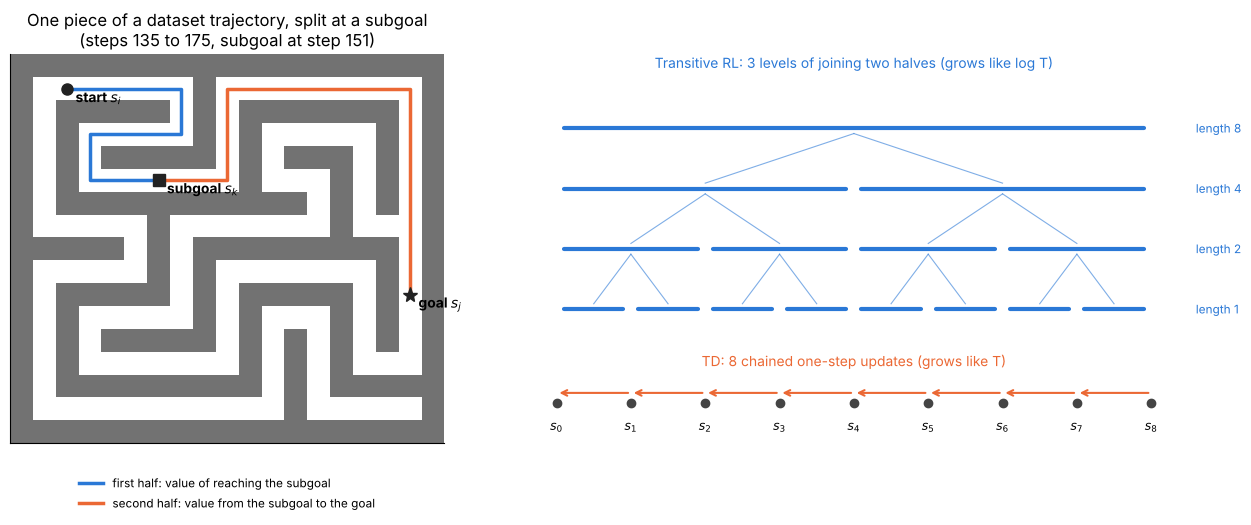

In [5]:
# Diagram 1: one update of Transitive RL on a real dataset trajectory (large maze).
env = ENVS["large"]
data = collect_dataset(env, seed=0)
# Pick a clean piece: 40 steps that never revisit a cell and end 40 steps from where they start.
n, i = next((n, i) for n in range(len(data["obs"])) for i in range(0, 150, 5)
            if len(set(data["obs"][n][i:i + 41])) == 41 and env.dist[data["obs"][n][i], data["obs"][n][i + 40]] >= 40)
traj, j = data["obs"][n], i + 40
k = i + 16
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
ax.imshow(env.grid, cmap="Greys", vmin=0, vmax=1.6)
for (a, b), col, lab in [((i, k), COLORS["mine"], "first half: value of reaching the subgoal"),
                         ((k, j), COLORS["td"], "second half: value from the subgoal to the goal")]:
    rc = np.array([env.cells[s] for s in traj[a:b + 1]])
    ax.plot(rc[:, 1], rc[:, 0], color=col, lw=2.5, label=lab)
for idx, mk, name in [(i, "o", "start $s_i$"), (k, "s", "subgoal $s_k$"), (j, "*", "goal $s_j$")]:
    r, c = env.cells[traj[idx]]
    ax.plot(c, r, mk, color="#222", ms=11 if mk == "*" else 8)
    ax.annotate(name, (c, r), xytext=(6, -10), textcoords="offset points", fontsize=10, weight="bold")
ax.set_title(f"One piece of a dataset trajectory, split at a subgoal\n(steps {i} to {j}, subgoal at step {k})")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.2), fontsize=8.5, frameon=False)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

# Diagram 2: how many chained updates a path of 8 steps needs (TD: a chain, TRL: a tree).
ax = axes[1]
ax.set_xlim(-0.5, 8.5); ax.set_ylim(-0.6, 5.2); ax.axis("off")
for x in range(9):
    ax.plot(x, 0, "o", color="#444", ms=6)
    ax.text(x, -0.4, f"$s_{x}$", ha="center", fontsize=9)
for x in range(8):  # TD: each value needs the one next to it
    ax.annotate("", (x, 0.15), (x + 1, 0.15), arrowprops=dict(arrowstyle="->", color=COLORS["td"], lw=1.5))
ax.text(4, 0.55, "TD: 8 chained one-step updates (grows like T)", ha="center", color=COLORS["td"], fontsize=10)
for level, span in enumerate([1, 2, 4, 8]):  # TRL: pieces join in pairs
    y = 1.4 + 0.9 * level
    for a in range(0, 8, span):
        ax.plot([a + 0.1, a + span - 0.1], [y, y], color=COLORS["mine"], lw=3, solid_capstyle="round")
        if span > 1:  # this piece is made by joining the two pieces below it
            for x in (a + span / 4, a + 3 * span / 4):
                ax.plot([x, a + span / 2], [y - 0.9 + 0.08, y - 0.08], color=COLORS["mine"], lw=0.8, alpha=0.6)
    ax.text(8.6, y, f"length {span}", va="center", fontsize=8.5, color=COLORS["mine"])
ax.text(4, 5.0, "Transitive RL: 3 levels of joining two halves (grows like log T)", ha="center",
        color=COLORS["mine"], fontsize=10)
plt.tight_layout(); plt.show()

## 4. Training and testing

Each method gets the same data and the same number of updates (batches of 1,024 pieces). The test is 200 fixed start-goal pairs at least 5 steps apart; the agent always takes its best-rated move and must reach the goal within 100 / 300 / 600 steps.

In [6]:
MAX_EPISODE_STEPS = {"medium": 100, "large": 300, "giant": 600}
STEPS = {"medium": 10000, "large": 20000, "giant": 100000}


def make_tasks(env, num_tasks=200, min_dist=5, seed=123):
    rng = np.random.default_rng(seed)
    pairs = np.argwhere((env.dist >= min_dist) & np.isfinite(env.dist))
    sel = pairs[rng.choice(len(pairs), size=num_tasks, replace=False)]
    return sel[:, 0], sel[:, 1]


def run_episodes(agent, env, s, g, max_steps, rng):
    cur, done = s.copy(), s == g
    for _ in range(max_steps):
        if done.all():
            break
        cur = np.where(done, cur, env.next_state[cur, agent.act(cur, g, rng)])
        done |= cur == g
    return done


def evaluate(agent, env, layout):
    starts, goals = make_tasks(env)
    success = run_episodes(agent, env, starts, goals, MAX_EPISODE_STEPS[layout], np.random.default_rng(0)).mean()
    n = env.num_states
    ss, gg = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")
    ss, gg = ss[ss != gg], gg[ss != gg]
    dist_err = np.median(np.abs(agent.distance(ss, gg) - env.dist[ss, gg]))
    return float(success), float(dist_err)


def train(method, layout, steps, seed=0, batch_size=1024, n_evals=20):
    env = ENVS[layout]
    rng = np.random.default_rng(seed)
    data = collect_dataset(env, seed=seed)
    agent = PaperAgent(env.num_states) if method == "paper" else Agent(method, env.num_states)
    curve = []
    for step in range(1, steps + 1):
        agent.update(sample_batch(data, batch_size, rng, paper_pairs=(method == "paper")))
        if step % (steps // n_evals) == 0:
            curve.append((step, *evaluate(agent, env, layout)))
    return agent, curve


results, t0 = {}, time.time()
for layout in STEPS:
    for m in METHODS:
        results[(layout, m)] = train(m, layout, STEPS[layout])
        print(f"{layout} maze, {LABELS[m]}: {results[(layout, m)][1][-1][1]:.1%} of test tasks solved"
              f"   ({time.time() - t0:.0f}s)")

medium maze, My method: 100.0% of test tasks solved   (5s)


medium maze, Paper-faithful: 67.0% of test tasks solved   (14s)


medium maze, TD: 100.0% of test tasks solved   (19s)


medium maze, MC: 8.0% of test tasks solved   (24s)


large maze, My method: 99.5% of test tasks solved   (33s)


large maze, Paper-faithful: 76.0% of test tasks solved   (53s)


... (2 outputs left out)

giant maze, My method: 78.5% of test tasks solved   (106s)


giant maze, Paper-faithful: 19.0% of test tasks solved   (636s)


giant maze, TD: 63.0% of test tasks solved   (676s)


giant maze, MC: 1.5% of test tasks solved   (703s)


## 5. Results

**Share of the 200 test tasks solved**

| Maze | My method | Paper-faithful | TD | MC |
|---|---|---|---|---|
| medium (10,000 updates) | 100.0% | 67.0% | 100.0% | 8.0% |
| large (20,000 updates) | 99.5% | 76.0% | 97.5% | 0.5% |
| giant (100,000 updates) | 78.5% | 19.0% | 63.0% | 1.5% |

**Error in the learned distance to the goal** (typical gap between the learned and the true number of steps)

| Maze | My method | Paper-faithful | TD | MC |
|---|---|---|---|---|
| medium | 0 steps | 839 steps | 0 steps | 26 steps |
| large | 0 steps | 495 steps | 0 steps | 19 steps |
| giant | 0 steps | 820 steps | 221 steps | 30 steps |

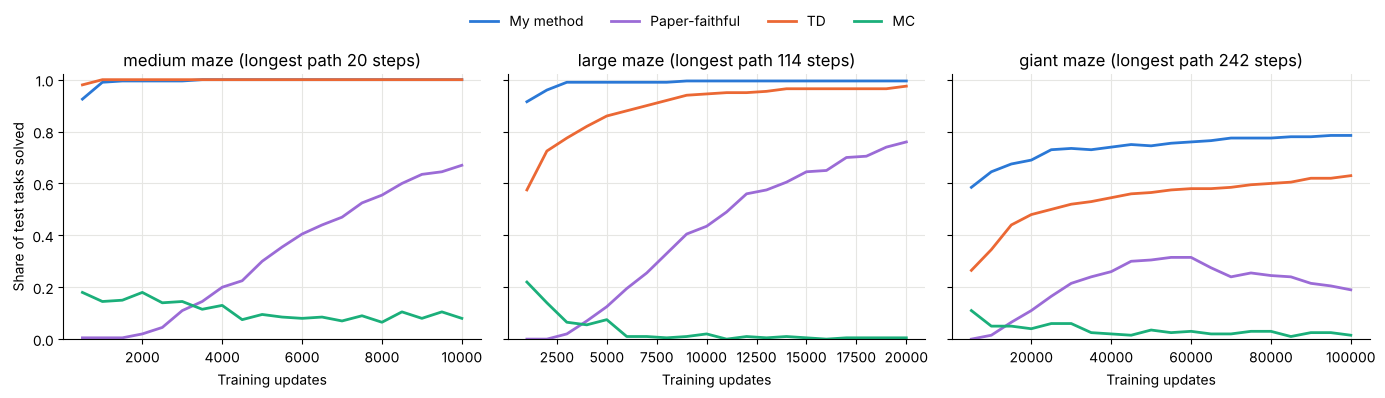

In [7]:
rows = ["| Maze | " + " | ".join(LABELS[m] for m in METHODS) + " |", "|---" * (len(METHODS) + 1) + "|"]
for layout in STEPS:
    rows.append(f"| {layout} ({STEPS[layout]:,} updates) | "
                + " | ".join(f"{results[(layout, m)][1][-1][1]:.1%}" for m in METHODS) + " |")
rows += ["", "**Error in the learned distance to the goal** (typical gap between the learned and the true number of steps)", "",
         rows[0], rows[1]]
for layout in STEPS:
    rows.append(f"| {layout} | " + " | ".join(f"{results[(layout, m)][1][-1][2]:.0f} steps" for m in METHODS) + " |")
display(Markdown("**Share of the 200 test tasks solved**\n\n" + "\n".join(rows)))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, layout in zip(axes, STEPS):
    for m in METHODS:
        curve = np.array(results[(layout, m)][1])
        ax.plot(curve[:, 0], curve[:, 1], color=COLORS[m], lw=2, label=LABELS[m])
    ax.set_title(f"{layout} maze (longest path {int(ENVS[layout].dist.max())} steps)")
    ax.set_xlabel("Training updates"); ax.set_ylim(0, 1.02)
axes[0].set_ylabel("Share of test tasks solved")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()

**How to read this.** The table gives the final share of test tasks each method solves, and how far its learned distances are from the truth. The figure shows the same success rate during training: a line that rises earlier means the method learns faster.

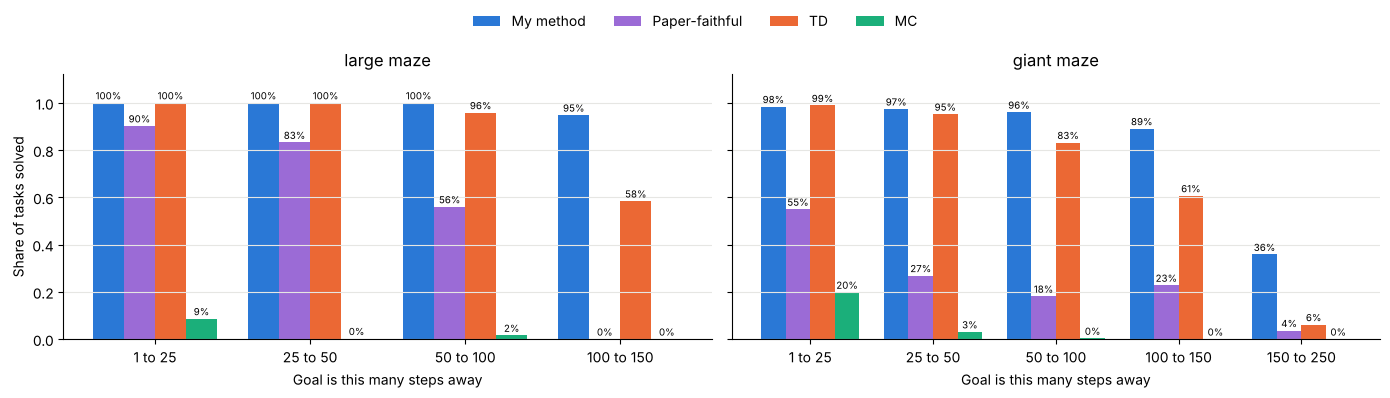

In [8]:
BUCKETS = [(1, 25), (25, 50), (50, 100), (100, 150), (150, 250)]


def success_by_distance(agent, env, n_pairs=3000, max_steps=600, seed=0):
    rng = np.random.default_rng(seed)
    n = env.num_states
    idx = rng.choice(n * n, n_pairs, replace=False)
    s, g = idx // n, idx % n
    s, g = s[s != g], g[s != g]
    done = run_episodes(agent, env, s, g, max_steps, rng)
    d = env.dist[s, g]
    return {b: done[(d >= b[0]) & (d < b[1])].mean() for b in BUCKETS if ((d >= b[0]) & (d < b[1])).any()}


fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, layout in zip(axes, ["large", "giant"]):
    table = {m: success_by_distance(results[(layout, m)][0], ENVS[layout]) for m in METHODS}
    buckets = list(table["mine"])
    x = np.arange(len(buckets))
    for off, m in zip([-0.3, -0.1, 0.1, 0.3], METHODS):
        vals = [table[m][b] for b in buckets]
        bars = ax.bar(x + off, vals, width=0.2, color=COLORS[m], label=LABELS[m])
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015, f"{v:.0%}", ha="center", fontsize=7)
    ax.set_xticks(x, [f"{lo} to {hi}" for lo, hi in buckets])
    ax.set_xlabel("Goal is this many steps away"); ax.set_title(f"{layout} maze")
    ax.set_ylim(0, 1.12); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Share of tasks solved")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()

**How to read this.** 3,000 random start-goal pairs, grouped by how far apart they are. Each bar is the share solved by one method.

**Summary of the results**
* **My method** solves the most tasks on every maze and learns the exact distances. Its lead over TD grows with the distance to the goal, which is the paper's main claim: splitting a path in half at a subgoal spreads value over long distances much faster than one step at a time.
* **Paper-faithful** (the paper's recipe exactly, in a table) solves 67% / 76% / 19% of the tasks, and its distances are hundreds of steps off. Each update only nudges a value toward a target from a slowly moving target table, so value spreads slowly (see the animation), and on the giant maze it peaks at about 32% and then gets worse. The paper's own rule for tables is the exact max that my method uses; the soft loss is there because a neural network cannot take an exact max safely.
* **TD** works but is slower and weaker on far goals, because value has to travel back one step per update.
* **MC** fails because it learns the noisy distances the data actually took and cannot join pieces of different trajectories.

## 6. Animations

**How the value spreads during training.** For one goal ★ in the large maze, each panel shows the value a method has learned for every cell (bright = the goal is known to be close, dark = not known to be reachable yet). TD spreads value outwards one step per update; Transitive RL joins known pieces, so value reaches far cells much sooner.

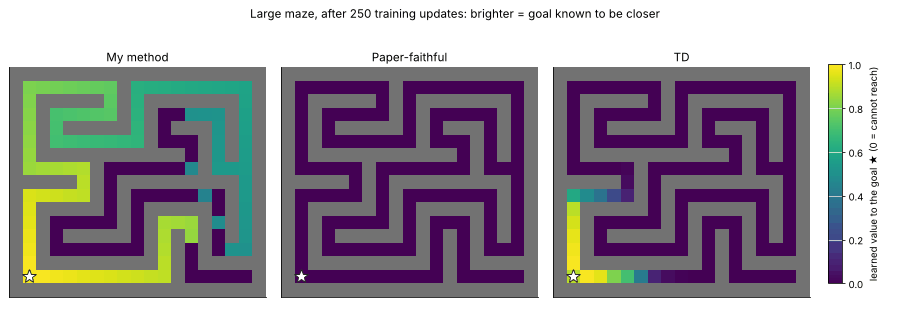

In [9]:
# Animation: how the learned value to one goal spreads through the maze during training.
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display


def value_snapshots(method, layout, goal, steps, every):
    env, rng = ENVS[layout], np.random.default_rng(0)
    data = collect_dataset(env, seed=0)
    agent = PaperAgent(env.num_states) if method == "paper" else Agent(method, env.num_states)
    snaps = []
    for step in range(1, steps + 1):
        agent.update(sample_batch(data, 1024, rng, paper_pairs=(method == "paper")))
        if step % every == 0:
            snaps.append(agent.Q[:, :, goal].max(-1).copy())
    return snaps


layout, goal_cell = "large", (15, 1)
env = ENVS[layout]
goal = env.cell_to_id[goal_cell]
spread_methods = ["mine", "paper", "td"]
EVERY, N_STEPS = 250, 10000
snaps = {m: value_snapshots(m, layout, goal, N_STEPS, EVERY) for m in spread_methods}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
fig.subplots_adjust(left=0.01, right=0.89, top=0.85, bottom=0.02, wspace=0.06)
images = {}
for ax, m in zip(axes, spread_methods):
    img = np.full(env.grid.shape, np.nan)
    images[m] = (ax.imshow(img, cmap="viridis", vmin=0, vmax=1), img)
    ax.imshow(np.where(env.grid, 1.0, np.nan), cmap="Greys", vmin=0, vmax=1.6)
    ax.plot(goal_cell[1], goal_cell[0], "*", color="white", ms=15, mec="#222")
    ax.set_title(LABELS[m]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.colorbar(images["mine"][0], cax=fig.add_axes([0.91, 0.12, 0.015, 0.68]),
             label="learned value to the goal ★ (0 = cannot reach)")
title = fig.suptitle("")


def draw(t):
    for m in spread_methods:
        im, img = images[m]
        for s, (r, c) in enumerate(env.cells):
            img[r, c] = snaps[m][t][s]
        im.set_data(img)
    title.set_text(f"Large maze, after {(t + 1) * EVERY:,} training updates: brighter = goal known to be closer")
    return []


frames = list(range(len(snaps["mine"]))) + [len(snaps["mine"]) - 1] * 10
FuncAnimation(fig, draw, frames=frames).save("value_spreading.gif", writer=PillowWriter(fps=8), dpi=70)
plt.close(fig)
display(Image(filename="value_spreading.gif"))

**The same long task, tried by each method.** One task in the giant maze, at least 150 steps long, picked as the first one (in a fixed random order) that my method solves and TD does not, so it is an illustration, not a fair sample. Each method always takes its best-rated move.

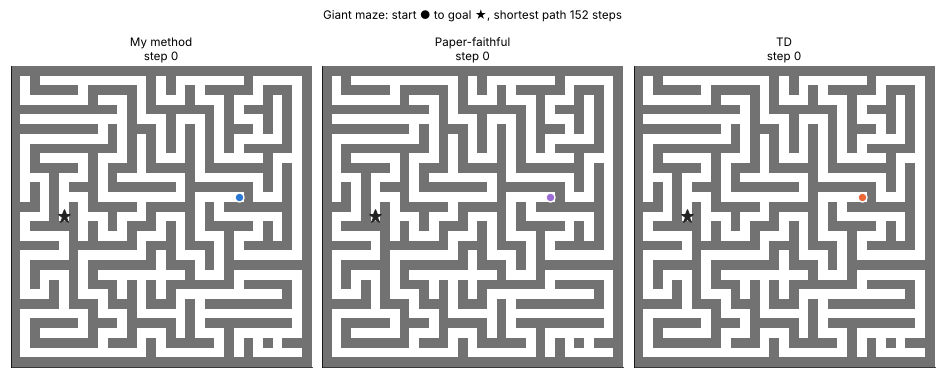

In [10]:
# Animation: the methods trying the same long task in the giant maze.
def rollout(agent, env, s, g, max_steps):
    rng, path = np.random.default_rng(0), [s]
    while len(path) <= max_steps and s != g:
        s = int(env.next_state[s, agent.act(np.array([s]), np.array([g]), rng)[0]])
        path.append(s)
    return path


env = ENVS["giant"]
agents = {m: results[("giant", m)][0] for m in ["mine", "paper", "td"]}
# In a fixed random order, the first task at least 150 steps long that my method solves and TD does not.
pairs = np.argwhere(env.dist >= 150)
pairs = pairs[np.random.default_rng(1).permutation(len(pairs))]
solved = lambda m, s, g: rollout(agents[m], env, s, g, 600)[-1] == g
s, g = next((s, g) for s, g in pairs[:2000] if solved("mine", s, g) and not solved("td", s, g))
paths = {m: np.array([env.cells[p] for p in rollout(a, env, s, g, 600)]) for m, a in agents.items()}

fig, axes = plt.subplots(1, 3, figsize=(13.5, 5.4))
art = {}
for ax, m in zip(axes, agents):
    ax.imshow(env.grid, cmap="Greys", vmin=0, vmax=1.6)
    ax.plot(*env.cells[s][::-1], "o", color="#222", ms=8)
    ax.plot(*env.cells[g][::-1], "*", color="#222", ms=14)
    trail, = ax.plot([], [], color=COLORS[m], lw=2)
    dot, = ax.plot([], [], "o", color=COLORS[m], ms=9, mec="white", mew=1.5)
    art[m] = (trail, dot, ax.set_title(LABELS[m]))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle(f"Giant maze: start ● to goal ★, shortest path {int(env.dist[s, g])} steps")


def draw(t):
    for m, (trail, dot, title) in art.items():
        p = paths[m][: t + 1]
        trail.set_data(p[:, 1], p[:, 0]); dot.set_data([p[-1, 1]], [p[-1, 0]])
        n = len(paths[m]) - 1
        if t < n:
            status = f"step {t}"
        elif tuple(paths[m][-1]) == env.cells[g]:
            status = f"reached the goal in {n} steps"
        else:
            status = f"failed: still lost after {n} steps"
        title.set_text(f"{LABELS[m]}\n{status}")
    return []


n_frames = max(len(p) for p in paths.values())
plt.tight_layout(rect=(0, 0, 1, 0.92))
FuncAnimation(fig, draw, frames=list(range(0, n_frames, 3)) + [n_frames - 1] * 20).save(
    "rollouts_giant.gif", writer=PillowWriter(fps=20), dpi=70)
plt.close(fig)
display(Image(filename="rollouts_giant.gif"))